In [1]:
%pip install pandas numpy matplotlib scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\SanketKumar\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [13]:
import os
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully")

Libraries imported successfully


<h2>Import the uncleaned CSV</h2>

In [14]:
file_path = "Tetuan_City_power_consumption_unclean.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(f"CSV file not found: {file_path}")

raw = pd.read_csv(file_path)

print("Original dataset shape:", raw.shape)
print("Column names:", raw.columns.tolist())

display(raw.head())

Original dataset shape: (52678, 11)
Column names: ['DateTime', 'Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows', 'Zone 1 Power Consumption', 'Zone 2  Power Consumption', 'Zone 3  Power Consumption', 'Zone 2 Power Consumption', 'Zone 3 Power Consumption']


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,NaN,15.74,74.8,0.082,0.059,0.07,36535.38462,29584.71074,15984.57831,NaN,NaN
1,NaN,15.28,58.26,0.08,512.4,158.3,33776.42586,26853.63608,10222.32893,NaN,NaN
2,NaN,16.3,35.46,0.09,436.4,476.3,30552.51064,19485.36585,14696.12903,NaN,NaN
3,02/05/2017 01:20,8.28,50.62,0.096,0.088,0.078,25175.59322,14877.81155,16492.70352,NaN,NaN
4,NaN,12.76,62.5,4.925,0.157,0.115,40270.76923,33567.76860,17615.42169,NaN,NaN


<h2>Inspect the original data</h2>

In [9]:
# Remove accidental spaces around column names
df.columns = df.columns.astype(str).str.strip()

print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isna().sum())

print("\nBlank strings per column:")
print(
    df.select_dtypes(include=["object", "string"])
      .apply(lambda col: col.astype("string").str.strip().eq("").sum())
)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nFirst 10 rows:")
display(df.head(10))

Column names:
['DateTime', 'Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows', 'Zone 1 Power Consumption', 'Zone 2  Power Consumption', 'Zone 3  Power Consumption', 'Zone 2 Power Consumption', 'Zone 3 Power Consumption']

Data types:
DateTime                      object
Temperature                   object
Humidity                      object
Wind Speed                    object
general diffuse flows         object
diffuse flows                 object
Zone 1 Power Consumption      object
Zone 2  Power Consumption    float64
Zone 3  Power Consumption    float64
Zone 2 Power Consumption      object
Zone 3 Power Consumption      object
dtype: object

Missing values per column:
DateTime                     31798
Temperature                    789
Humidity                       784
Wind Speed                     789
general diffuse flows          788
diffuse flows                  789
Zone 1 Power Consumption       787
Zone 2  Power Consumption        0
Zone 3

,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,NaN,15.74,74.8,0.082,0.059,0.07,36535.38462,29584.71074,15984.57831,NaN,NaN
1,NaN,15.28,58.26,0.08,512.4,158.3,33776.42586,26853.63608,10222.32893,NaN,NaN
2,NaN,16.3,35.46,0.09,436.4,476.3,30552.51064,19485.36585,14696.12903,NaN,NaN
3,02/05/2017 01:20,8.28,50.62,0.096,0.088,0.078,25175.59322,14877.81155,16492.70352,NaN,NaN
4,NaN,12.76,62.5,4.925,0.157,0.115,40270.76923,33567.76860,17615.42169,NaN,NaN
5,07/03/2017 07:10,23.8,87.3,4.915,103.1,84.1,25074.81728,16758.22785,16291.88285,NaN,NaN
6,11/12/2017 04:50,15.75,79.6,0.074,0.069,0.107,21470.76923,16129.33884,10583.13253,NaN,NaN
7,NaN,25.37,62.58,0.07,606.3,89.1,37497.21854,21237.00624,20363.81538,NaN,NaN
8,05/02/2017 18:20,NaN,32.19,0.074,124.2,106.4,34408.91803,20775.23220,17303.31984,NaN,NaN
9,NaN,13.74,71.7,0.08,0.026,0.171,43468.47458,25506.38298,25645.02513,NaN,NaN


<h2>Select the required columns</h2>

In [15]:
if raw.shape[1] < 9:
    raise ValueError(f"Expected at least 9 columns, found {raw.shape[1]}")

df = pd.DataFrame({
    "DateTime": raw.iloc[:, 0],
    "Temperature": raw.iloc[:, 1],
    "Humidity": raw.iloc[:, 2],
    "Wind Speed": raw.iloc[:, 3],
    "general diffuse flows": raw.iloc[:, 4],
    "diffuse flows": raw.iloc[:, 5],
    "Zone 1 Power Consumption": raw.iloc[:, 6],
    "Zone 2 Power Consumption": raw.iloc[:, 7],
    "Zone 3 Power Consumption": raw.iloc[:, 8]
})

print("Selected columns:", df.columns.tolist())
display(df.head())

Selected columns: ['DateTime', 'Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows', 'Zone 1 Power Consumption', 'Zone 2 Power Consumption', 'Zone 3 Power Consumption']


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,NaN,15.74,74.8,0.082,0.059,0.07,36535.38462,29584.71074,15984.57831
1,NaN,15.28,58.26,0.08,512.4,158.3,33776.42586,26853.63608,10222.32893
2,NaN,16.3,35.46,0.09,436.4,476.3,30552.51064,19485.36585,14696.12903
3,02/05/2017 01:20,8.28,50.62,0.096,0.088,0.078,25175.59322,14877.81155,16492.70352
4,NaN,12.76,62.5,4.925,0.157,0.115,40270.76923,33567.76860,17615.42169


<h2>Check data quality</h2>

In [16]:
print("Missing values:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDateTime examples:")
display(df[["DateTime"]].head(10))

print("\nData types:")
print(df.dtypes)

Missing values:
DateTime                    31798
Temperature                   789
Humidity                      784
Wind Speed                    789
general diffuse flows         788
diffuse flows                 789
Zone 1 Power Consumption      787
Zone 2 Power Consumption        0
Zone 3 Power Consumption        0
dtype: int64

Duplicate rows: 262

DateTime examples:


,DateTime
0,NaN
1,NaN
2,NaN
3,02/05/2017 01:20
4,NaN
5,07/03/2017 07:10
6,11/12/2017 04:50
7,NaN
8,05/02/2017 18:20
9,NaN



Data types:
DateTime                     object
Temperature                  object
Humidity                     object
Wind Speed                   object
general diffuse flows        object
diffuse flows                object
Zone 1 Power Consumption     object
Zone 2 Power Consumption    float64
Zone 3 Power Consumption    float64
dtype: object


<h2>Clean the data</h2>

In [17]:
numeric_columns = [
    "Temperature",
    "Humidity",
    "Wind Speed",
    "general diffuse flows",
    "diffuse flows",
    "Zone 1 Power Consumption",
    "Zone 2 Power Consumption",
    "Zone 3 Power Consumption"
]

original_rows = len(df)

df["DateTime"] = pd.to_datetime(
    df["DateTime"].astype("string").str.strip(),
    errors="coerce",
    format="mixed",
    dayfirst=False
)

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col].astype("string").str.strip(),
        errors="coerce"
    )

df[numeric_columns] = df[numeric_columns].replace(
    [np.inf, -np.inf], np.nan
)

print("Invalid timestamps:", df["DateTime"].isna().sum())
print("Invalid numeric values per column:")
print(df[numeric_columns].isna().sum())

Invalid timestamps: 31850
Invalid numeric values per column:
Temperature                 894
Humidity                    890
Wind Speed                  893
general diffuse flows       892
diffuse flows               894
Zone 1 Power Consumption    891
Zone 2 Power Consumption      0
Zone 3 Power Consumption      0
dtype: int64


<h2>Remove invalid rows and duplicates</h2>

In [18]:
invalid_dates = df["DateTime"].isna().sum()
df = df.dropna(subset=["DateTime"])

before_duplicates = len(df)
df = df.drop_duplicates()
duplicates_removed = before_duplicates - len(df)

before_missing = len(df)
df = df.dropna(subset=numeric_columns)
numeric_rows_removed = before_missing - len(df)

df = df.sort_values("DateTime").reset_index(drop=True)

print("Original rows:", original_rows)
print("Invalid timestamps removed:", invalid_dates)
print("Duplicates removed:", duplicates_removed)
print("Rows removed for missing numeric values:", numeric_rows_removed)
print("Final clean rows:", len(df))

if len(df) < 10:
    raise ValueError(
        "Too few valid rows remain. Check the DateTime format and source data."
    )

display(df.head())

Original rows: 52678
Invalid timestamps removed: 31850
Duplicates removed: 105
Rows removed for missing numeric values: 2041
Final clean rows: 18682


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.6962,16128.87538,20240.96386
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.07,0.085,29814.68354,19375.07599,20131.08434
2,2017-01-01 00:20:00,6.313,74.5,0.08,0.062,0.1,29128.10127,19006.68693,19668.43373
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.6962,17872.34043,18442.40964


<h2>Create time features</h2>

In [19]:
df["Year"] = df["DateTime"].dt.year
df["Month"] = df["DateTime"].dt.month
df["Day"] = df["DateTime"].dt.day
df["Hour"] = df["DateTime"].dt.hour
df["DayOfWeek"] = df["DateTime"].dt.dayofweek

display(df.head())

,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption,Year,Month,Day,Hour,DayOfWeek
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.6962,16128.87538,20240.96386,2017,1,1,0,6
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.07,0.085,29814.68354,19375.07599,20131.08434,2017,1,1,0,6
2,2017-01-01 00:20:00,6.313,74.5,0.08,0.062,0.1,29128.10127,19006.68693,19668.43373,2017,1,1,0,6
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711,2017,1,1,0,6
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.6962,17872.34043,18442.40964,2017,1,1,0,6


<h2>Save the cleaned CSV</h2>

In [20]:
cleaned_file = "Tetuan_City_power_consumption_cleaned.csv"

df.to_csv(cleaned_file, index=False)

print("Cleaned dataset saved:", cleaned_file)
print("Cleaned dataset shape:", df.shape)

Cleaned dataset saved: Tetuan_City_power_consumption_cleaned.csv
Cleaned dataset shape: (18682, 14)


<h2>Define features and target columns</h2>

In [21]:
features = [
    "Temperature",
    "Humidity",
    "Wind Speed",
    "general diffuse flows",
    "diffuse flows",
    "Year",
    "Month",
    "Day",
    "Hour",
    "DayOfWeek"
]

targets = [
    "Zone 1 Power Consumption",
    "Zone 2 Power Consumption",
    "Zone 3 Power Consumption"
]

print("Features:", features)
print("Targets:", targets)

Features: ['Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows', 'Year', 'Month', 'Day', 'Hour', 'DayOfWeek']
Targets: ['Zone 1 Power Consumption', 'Zone 2 Power Consumption', 'Zone 3 Power Consumption']


<h2>Split training and testing data</h2>

In [22]:
split_index = int(len(df) * 0.80)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

X_train = train_df[features]
X_test = test_df[features]

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

print("Training period:", train_df["DateTime"].min(), "to", train_df["DateTime"].max())
print("Testing period:", test_df["DateTime"].min(), "to", test_df["DateTime"].max())

Training rows: 14945
Testing rows: 3737
Training period: 2017-01-01 00:00:00 to 2017-10-08 10:10:00
Testing period: 2017-10-08 10:20:00 to 2017-12-12 23:50:00


<h2>Train the three Random Forest models</h2>

In [23]:
os.makedirs("models", exist_ok=True)

models = {}
predictions = {}
results = []

for target in targets:
    print("Training model:", target)

    y_train = train_df[target]
    y_test = test_df[target]

    model = RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    models[target] = model
    predictions[target] = y_pred

    safe_name = re.sub(
        r"[^a-zA-Z0-9]+", "_", target
    ).strip("_").lower()

    joblib.dump(model, f"models/{safe_name}.joblib")

    mse = mean_squared_error(y_test, y_pred)

    results.append({
        "Zone": target,
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_test, y_pred)
    })

print("All models trained successfully.")

Training model: Zone 1 Power Consumption
Training model: Zone 2 Power Consumption
Training model: Zone 3 Power Consumption
All models trained successfully.


<h2>Evaluate the models</h2>

In [24]:
results_df = pd.DataFrame(results)

print("Regression evaluation results:")
display(results_df.round(4))

results_df.to_csv(
    "regression_evaluation_results.csv",
    index=False
)

Regression evaluation results:


,Zone,MAE,MSE,RMSE,R2
0,Zone 1 Power Consumption,3557.2175,1.675547e+07,4093.3450,0.5871
1,Zone 2 Power Consumption,3608.6273,1.849716e+07,4300.8323,0.3517
2,Zone 3 Power Consumption,2530.9564,8.815957e+06,2969.1678,0.2275


<h2>Compare predictions and plot graphs</h2>

,DateTime,Zone 1 Actual,Zone 1 Predicted,Zone 1 Absolute Error,Zone 2 Actual,Zone 2 Predicted,Zone 2 Absolute Error,Zone 3 Actual,Zone 3 Predicted,Zone 3 Absolute Error
0,2017-10-08 10:20:00,32650.50328,31631.805926,1018.697354,18141.90871,18059.961518,81.947192,12558.78419,12250.370048,308.414142
1,2017-10-08 10:30:00,32978.20569,31616.185714,1362.019976,18380.91286,17965.425144,415.487716,12681.33739,12316.223724,365.113666
2,2017-10-08 10:40:00,32934.09190,31573.601771,1360.490129,18526.55602,18106.031462,420.524558,12786.38298,12364.293260,422.089720
3,2017-10-08 10:50:00,33375.22976,31420.321164,1954.908596,18358.50622,18186.866944,171.639276,12943.95137,12335.248648,608.702722
4,2017-10-08 11:10:00,33873.08534,31919.469558,1953.615782,18929.87552,18958.055859,28.180339,13089.84802,14316.479500,1226.631480
5,2017-10-08 11:20:00,33608.40263,31813.255183,1795.147447,18858.92116,19081.163726,222.242566,13253.25228,14060.512228,807.259948
6,2017-10-08 11:30:00,33847.87746,31708.008119,2139.869341,18989.62656,19039.786485,50.159925,13381.64134,13984.786760,603.145420
7,2017-10-08 11:40:00,34093.65427,31598.048043,2495.606227,19168.87967,18940.683380,228.196290,13679.27052,14003.267022,323.996502
8,2017-10-08 11:50:00,34484.37637,31281.285571,3203.090799,19434.02490,18846.982833,587.042067,13714.28571,14022.285490,307.999780
9,2017-10-08 12:00:00,34339.43107,32095.552582,2243.878488,19404.14938,19727.490639,323.341259,13679.27052,14783.952745,1104.682225


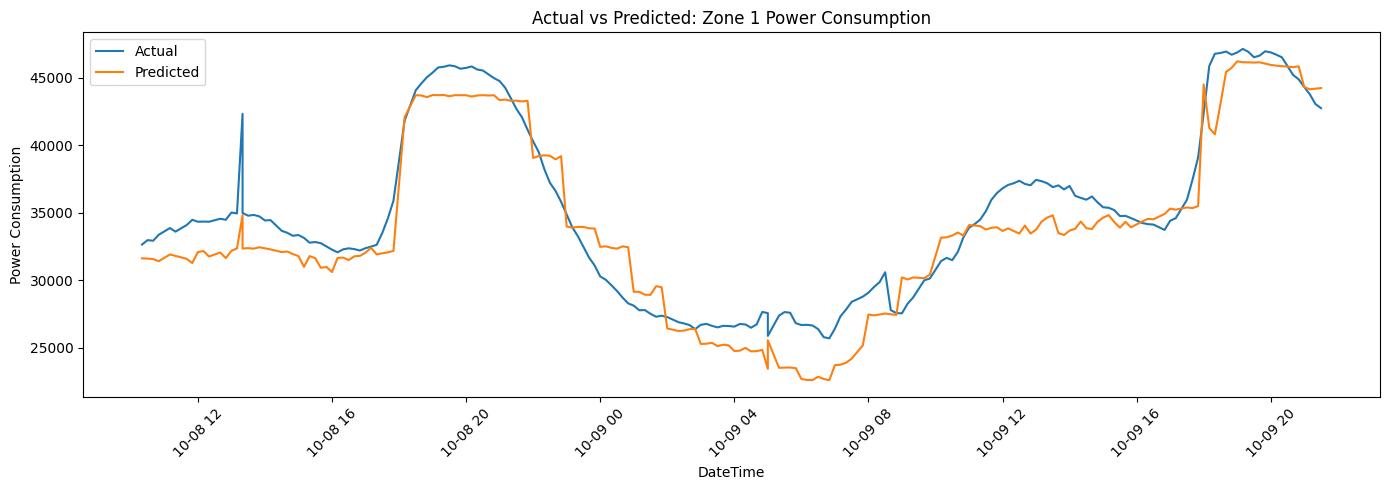

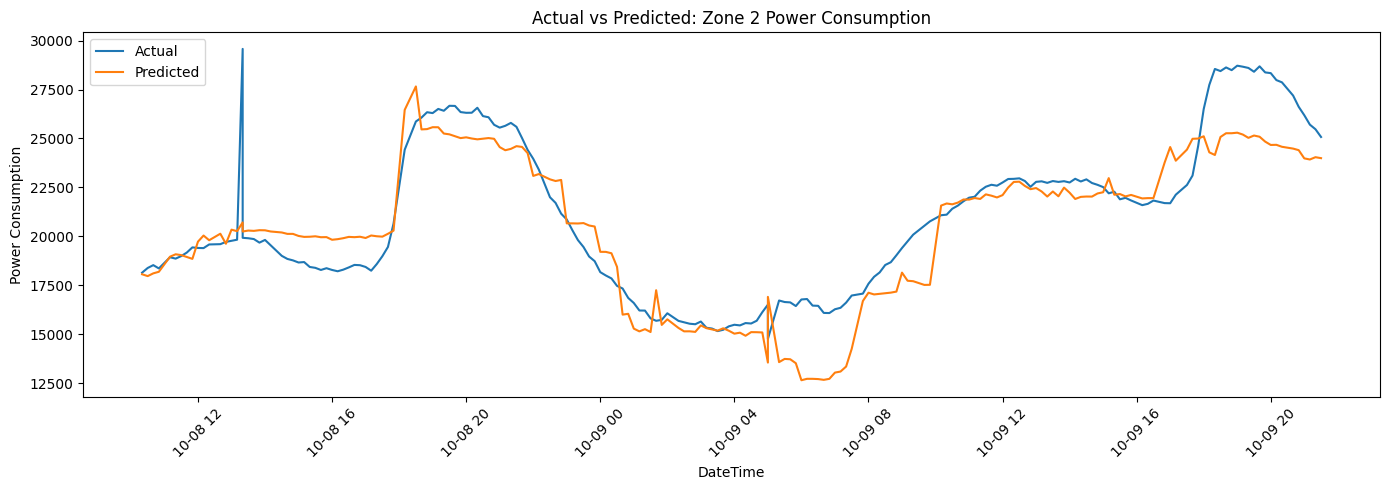

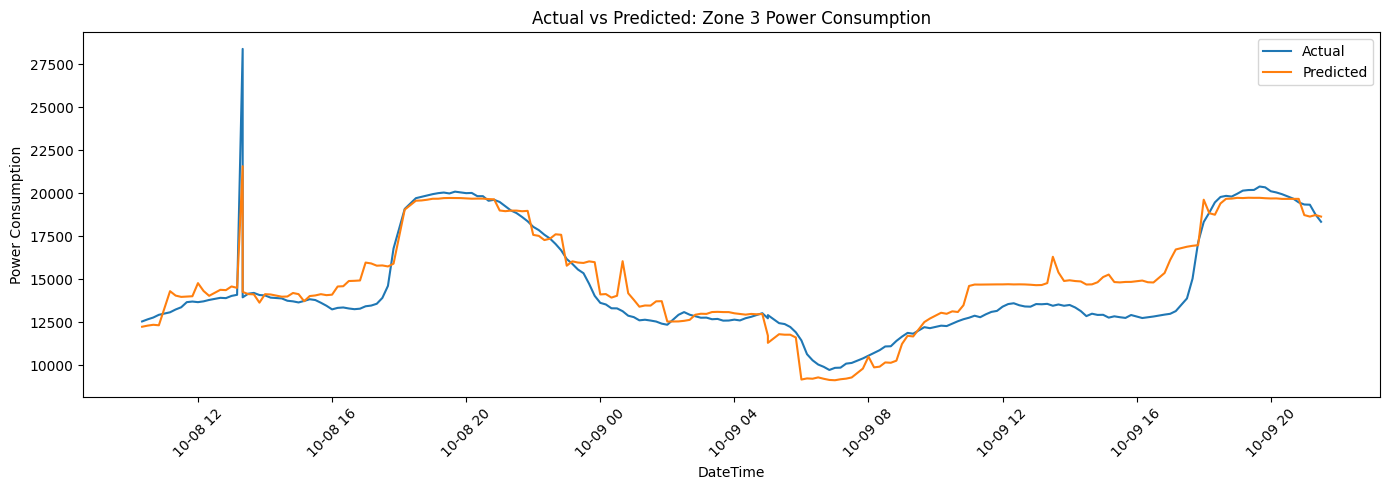

In [25]:
comparison = pd.DataFrame({
    "DateTime": test_df["DateTime"].to_numpy()
})

for target in targets:
    zone = target.replace(" Power Consumption", "")
    actual = test_df[target].to_numpy()
    predicted = predictions[target]

    comparison[f"{zone} Actual"] = actual
    comparison[f"{zone} Predicted"] = predicted
    comparison[f"{zone} Absolute Error"] = np.abs(actual - predicted)

display(comparison.head(20))

comparison.to_csv("regression_predictions.csv", index=False)

for target in targets:
    plt.figure(figsize=(14, 5))

    plt.plot(
        test_df["DateTime"].iloc[:200],
        test_df[target].iloc[:200].to_numpy(),
        label="Actual"
    )

    plt.plot(
        test_df["DateTime"].iloc[:200],
        predictions[target][:200],
        label="Predicted"
    )

    plt.title(f"Actual vs Predicted: {target}")
    plt.xlabel("DateTime")
    plt.ylabel("Power Consumption")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

<h2>Show feature importance and saved files</h2>

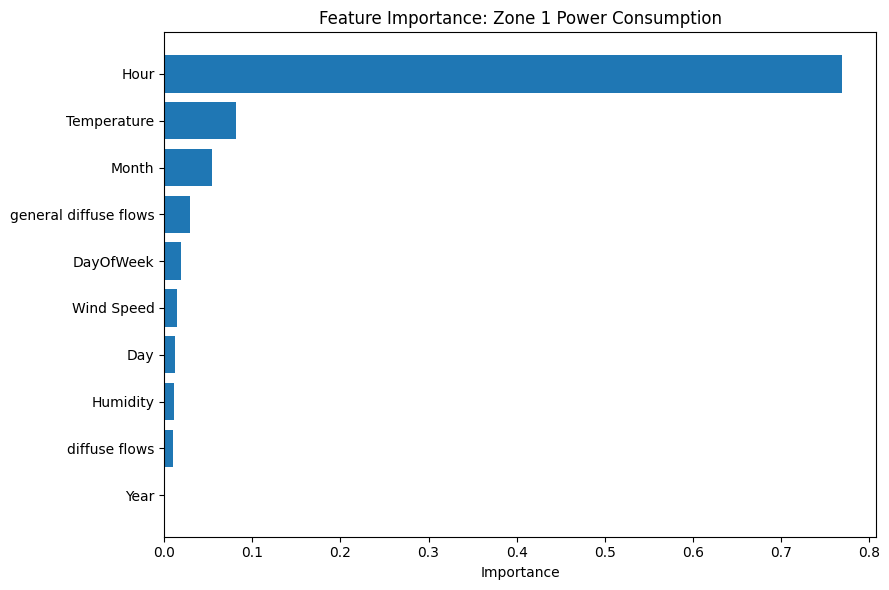

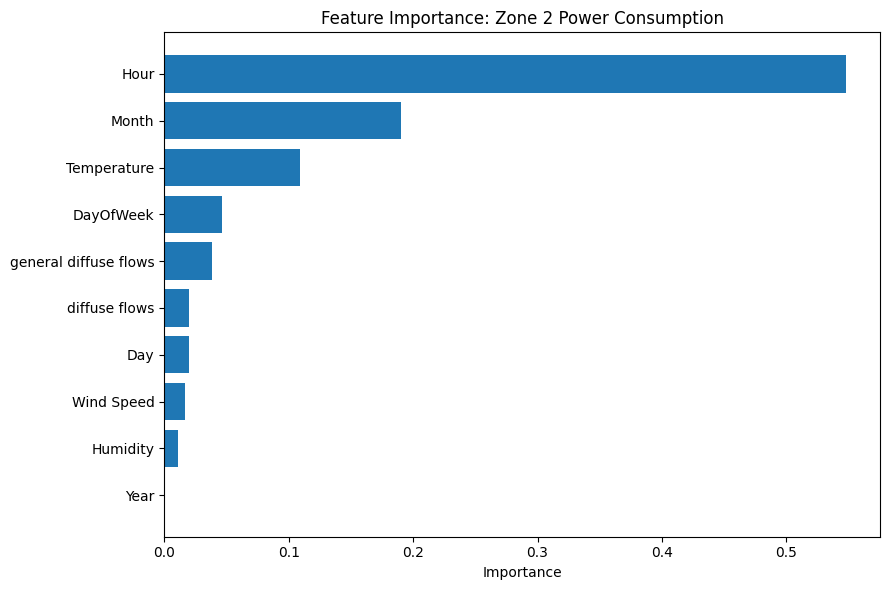

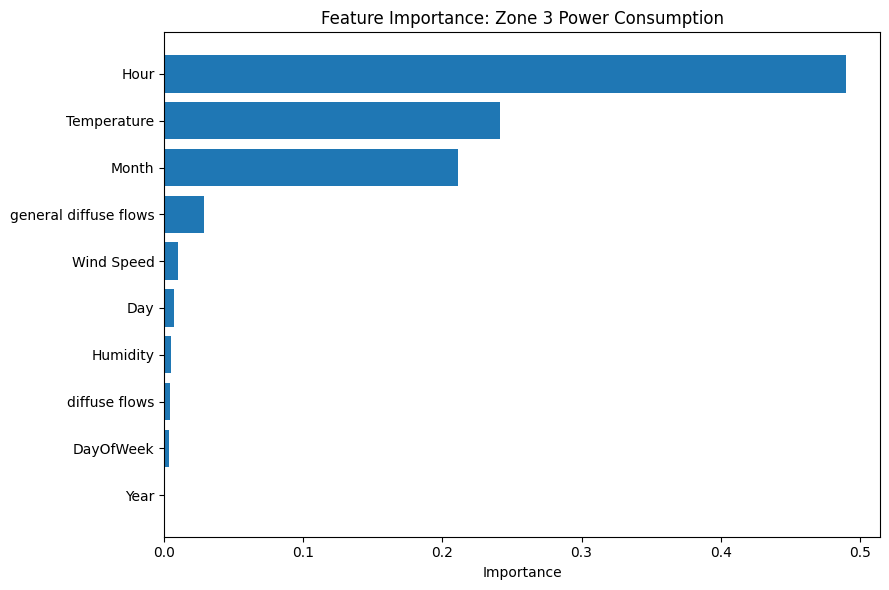


Saved output files:
Tetuan_City_power_consumption_cleaned.csv -> True
regression_evaluation_results.csv -> True
regression_predictions.csv -> True

Saved model files:
.ipynb_checkpoints
classification_thresholds.pkl
zone_1_power_consumption.joblib
zone_1_power_consumption.pkl
zone_1_power_consumption_classifier.pkl
zone_2_power_consumption.joblib
zone_2_power_consumption.pkl
zone_2_power_consumption_classifier.pkl
zone_3_power_consumption.joblib
zone_3_power_consumption.pkl
zone_3_power_consumption_classifier.pkl


In [30]:
for target in targets:
    importance = pd.DataFrame({
        "Feature": features,
        "Importance": models[target].feature_importances_
    }).sort_values("Importance", ascending=True)

    plt.figure(figsize=(9, 6))
    plt.barh(importance["Feature"], importance["Importance"])
    plt.title(f"Feature Importance: {target}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()

print("\nSaved output files:")
for filename in [
    cleaned_file,
    "regression_evaluation_results.csv",
    "regression_predictions.csv"
]:
    print(filename, "->", os.path.exists(filename))

print("\nSaved model files:")
for filename in sorted(os.listdir("models")):
    print(filename)

**Line plot — Actual vs predicted**

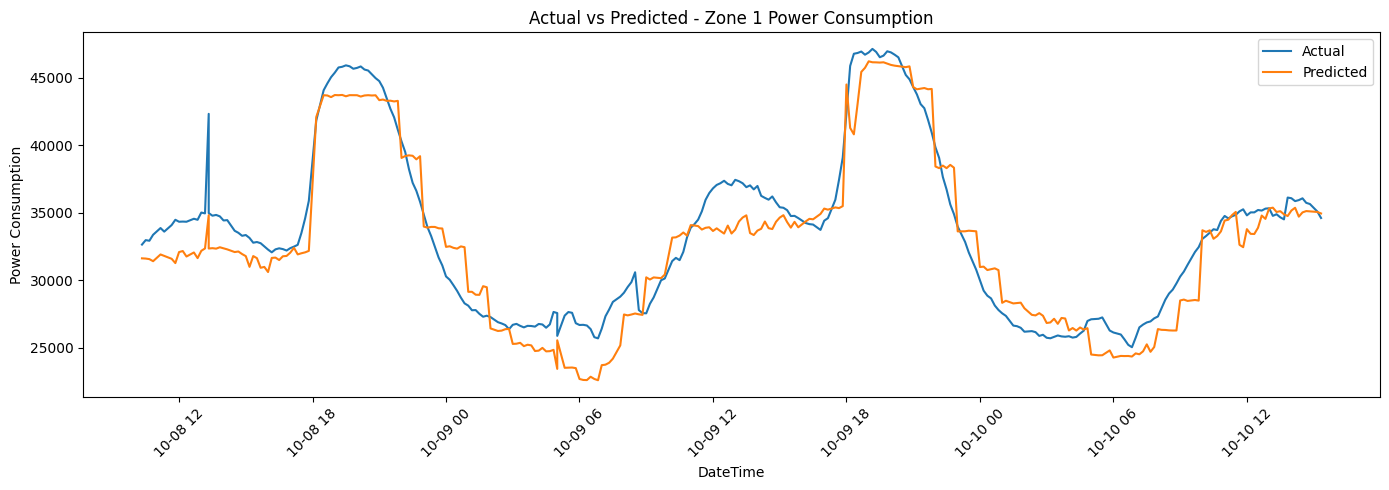

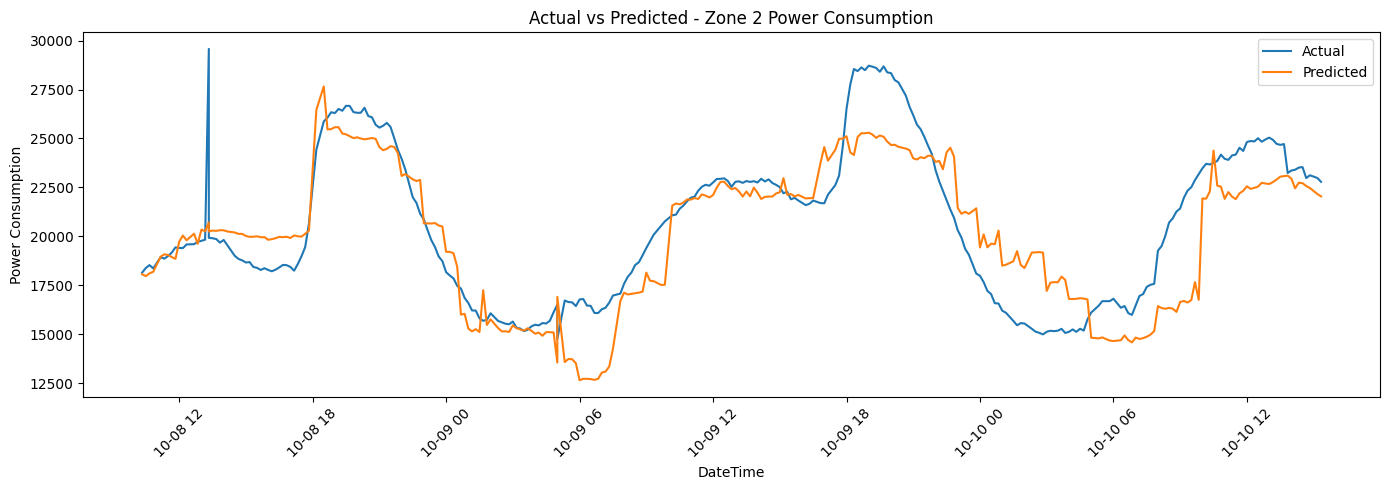

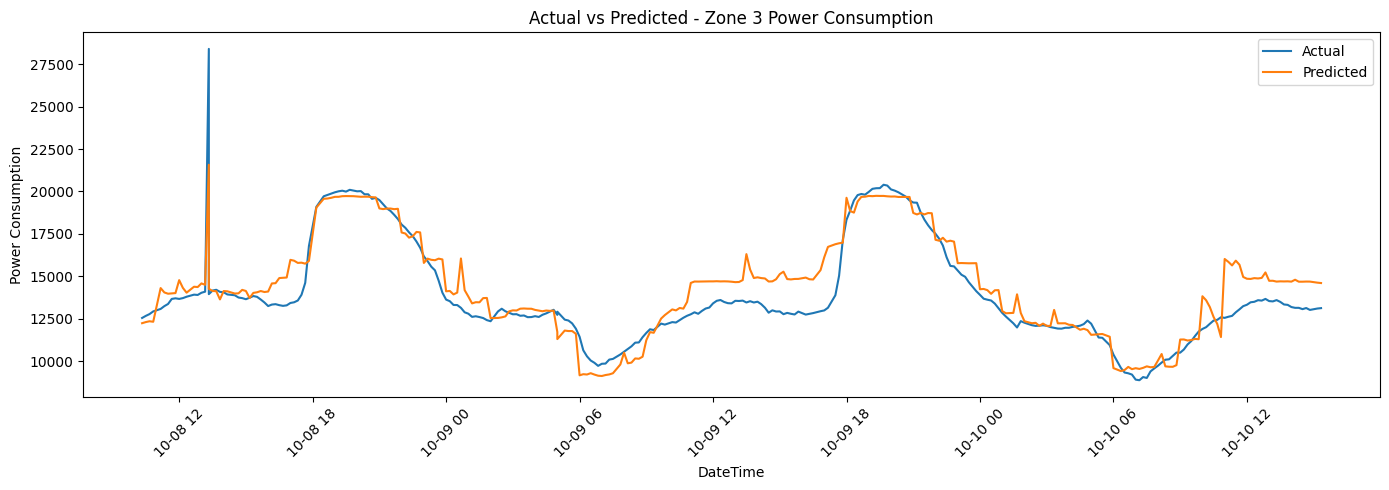

In [34]:
for target in targets:
    plt.figure(figsize=(14, 5))

    plt.plot(
        test_df["DateTime"].iloc[:300],
        test_df[target].iloc[:300],
        label="Actual"
    )

    plt.plot(
        test_df["DateTime"].iloc[:300],
        predictions[target][:300],
        label="Predicted"
    )

    plt.title(f"Actual vs Predicted - {target}")
    plt.xlabel("DateTime")
    plt.ylabel("Power Consumption")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

**Scatter plot — Actual vs predicted**

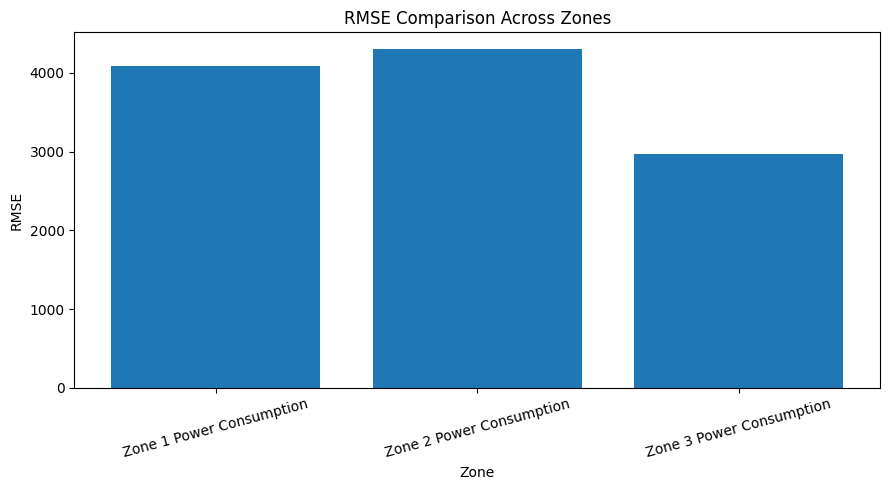

In [35]:
plt.figure(figsize=(9, 5))

plt.bar(results_df["Zone"], results_df["RMSE"])

plt.title("RMSE Comparison Across Zones")
plt.xlabel("Zone")
plt.ylabel("RMSE")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

<h2>Histogram — Distribution of prediction errors</h2>

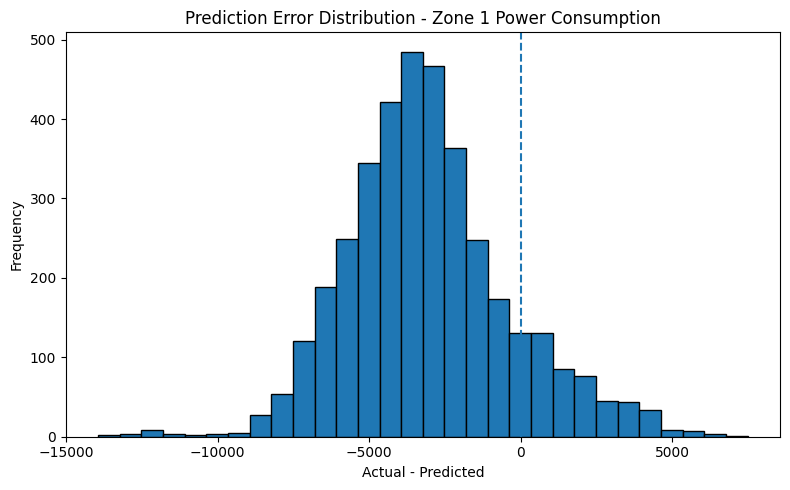

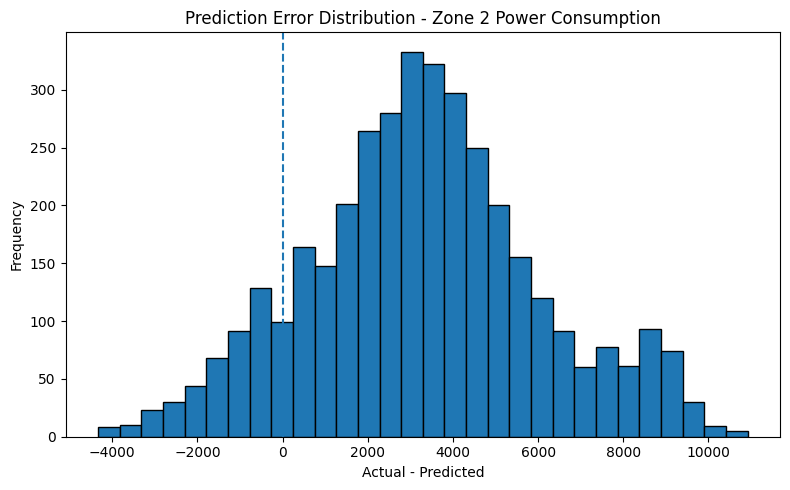

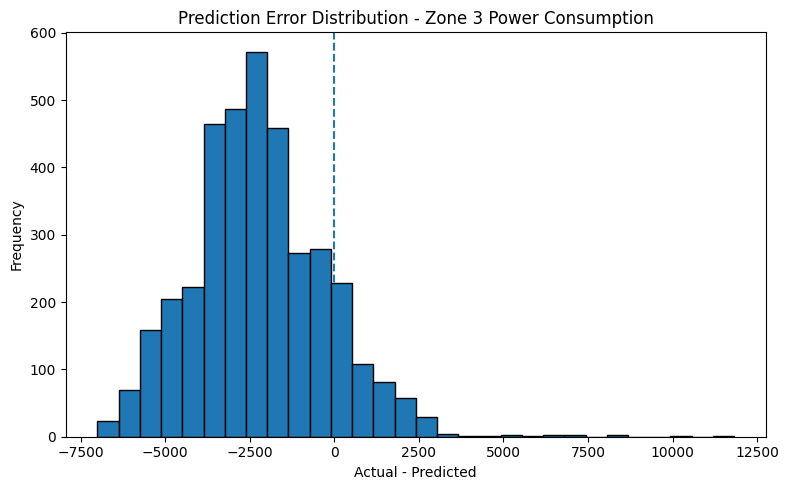

In [36]:
for target in targets:
    errors = (
        test_df[target].to_numpy()
        - predictions[target]
    )

    plt.figure(figsize=(8, 5))
    plt.hist(errors, bins=30, edgecolor="black")

    plt.axvline(0, linestyle="--")
    plt.title(f"Prediction Error Distribution - {target}")
    plt.xlabel("Actual - Predicted")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

<h2>Feature importance — Horizontal bar chart</h2>

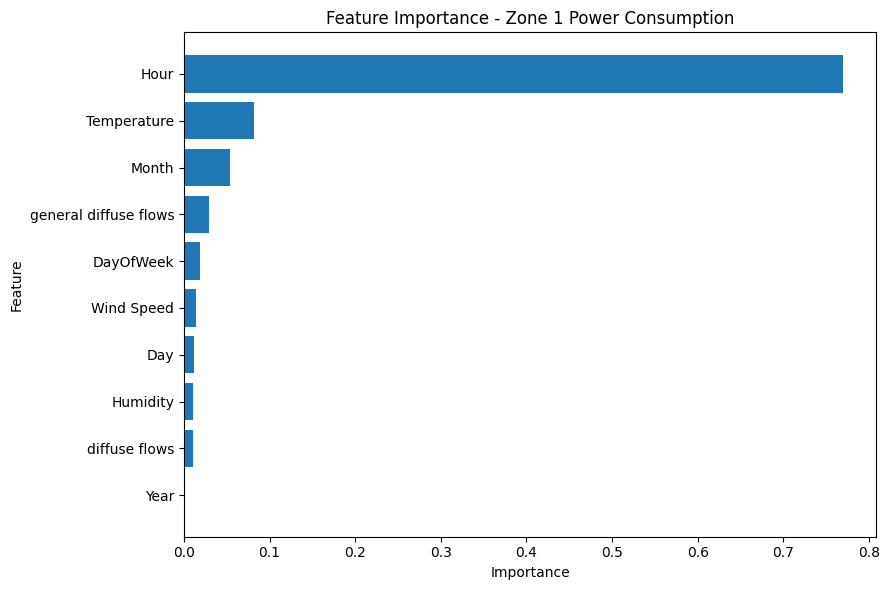

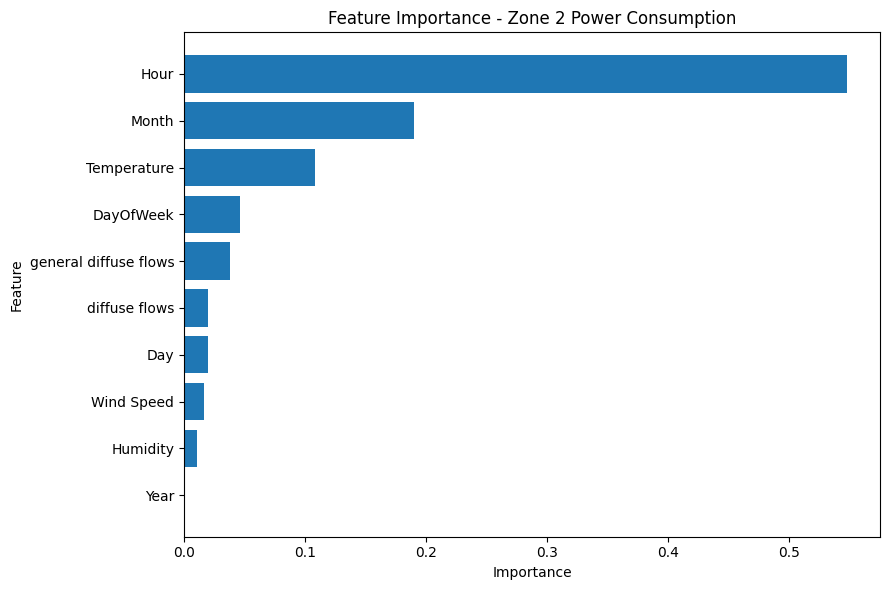

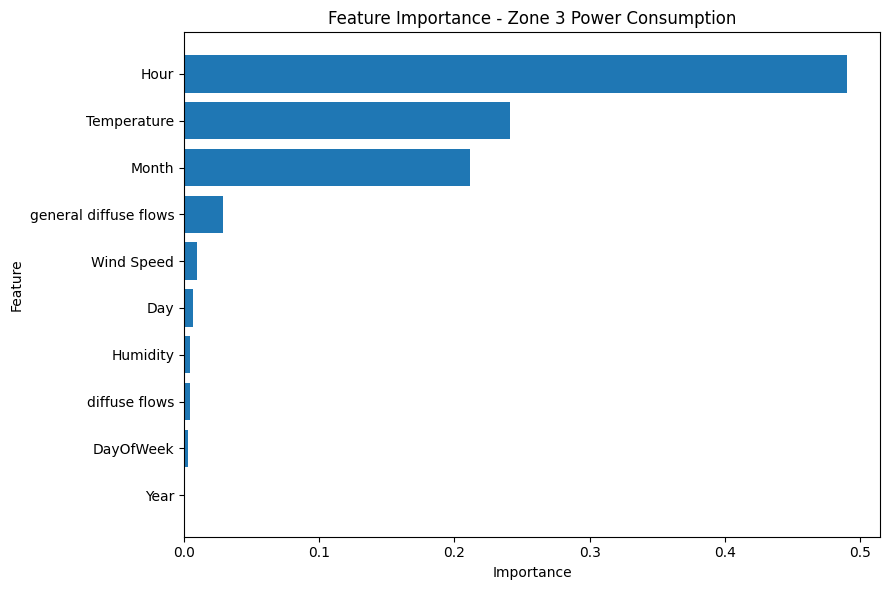

In [40]:
for target in targets:
    importance_df = pd.DataFrame({
        "Feature": features,
        "Importance": models[target].feature_importances_
    }).sort_values("Importance")

    plt.figure(figsize=(9, 6))
    plt.barh(
        importance_df["Feature"],
        importance_df["Importance"]
    )

    plt.title(f"Feature Importance - {target}")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

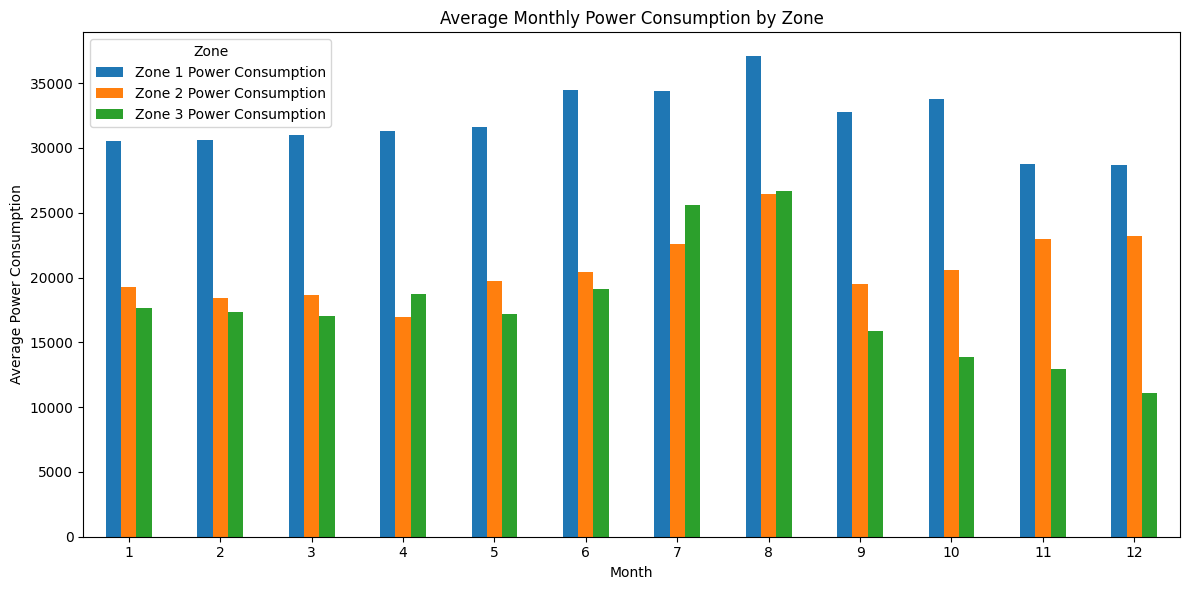

In [39]:
monthly_avg = df.groupby("Month")[targets].mean()

monthly_avg.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Monthly Power Consumption by Zone")
plt.xlabel("Month")
plt.ylabel("Average Power Consumption")
plt.xticks(rotation=0)
plt.legend(title="Zone")
plt.tight_layout()
plt.show()